<a href="https://colab.research.google.com/github/anasarshad7677-netizen/Complete-ML-repo/blob/main/17_outliers_handlings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv("/content/placement.csv")

/tmp/ipykernel_1527/617556415.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'])
/tmp/ipykernel_1527/617556415.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placement_exam_marks'])


<Axes: xlabel='placement_exam_marks', ylabel='Density'>

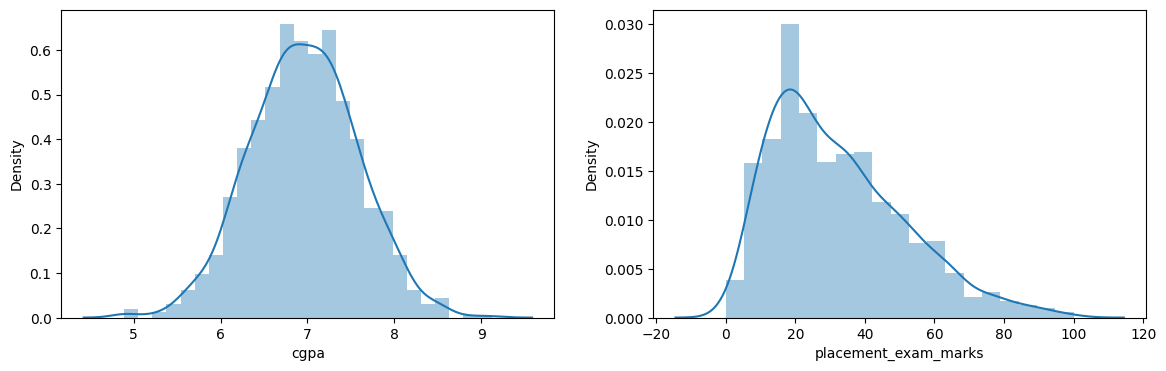

In [8]:
plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'])
plt.subplot(1,2,2)
sns.distplot(df['placement_exam_marks'])

In [9]:
print(f"what is the mininum cgpa {df['cgpa'].min()}")
print(f"what is the maximum cgpa {df['cgpa'].max()}")
print(f"what is the minimum placement_exam_marks {df['placement_exam_marks'].min()}")
print(f"what is the maximum placement_exam_marks {df['placement_exam_marks'].max()}")

what is the mininum cgpa 4.89
what is the maximum cgpa 9.12
what is the minimum placement_exam_marks 0.0
what is the maximum placement_exam_marks 100.0


In [36]:
upper_limit = df['cgpa'].mean()+3*df['cgpa'].std()
lower_limit =df['cgpa'].mean()-3*df['cgpa'].std()

In [12]:
df[(df['cgpa']>8.80 )|(df['cgpa']<5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [15]:
new_df = df[(df['cgpa']<8.80 )&(df['cgpa']>5.11)]
new_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


In [16]:
df['cgpa_Zscore']=(df['cgpa']-df['cgpa'].mean())/df['cgpa'].std()


In [17]:
df.head()

,cgpa,placement_exam_marks,placed,cgpa_Zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [19]:
df[df['cgpa_Zscore']< -3]

,cgpa,placement_exam_marks,placed,cgpa_Zscore
485,4.92,44.0,1,-3.314251
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [21]:
df[df['cgpa_Zscore']> 3]

,cgpa,placement_exam_marks,placed,cgpa_Zscore
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062


In [27]:
df[(df['cgpa_Zscore' ]> 3) | (df['cgpa_Zscore']< -3)]

,cgpa,placement_exam_marks,placed,cgpa_Zscore
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


# **capping**


In [37]:
lower_limit

np.float64(5.113546374602832)

In [38]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

In [41]:
df['cgpa'].describe()

,cgpa
count,1000.000000
mean,6.961499
std,0.612688
min,5.113546
25%,6.550000
50%,6.960000
75%,7.370000
max,8.808934


# **using iqr method **

In [49]:
df_new = df[['cgpa','placement_exam_marks','placed']]

In [50]:
df_new

,cgpa,placement_exam_marks,placed
0,7.190000,26.0,1
1,7.460000,38.0,1
2,7.540000,40.0,1
3,6.420000,8.0,1
4,7.230000,17.0,0
...,...,...,...
995,8.808934,44.0,1
996,8.808934,65.0,1
997,5.113546,34.0,0
998,8.620000,46.0,1


/tmp/ipykernel_1527/103218262.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_new['cgpa'])
/tmp/ipykernel_1527/103218262.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_new['placement_exam_marks'])


Text(0.5, 1.0, 'this is the distribution for the placement')

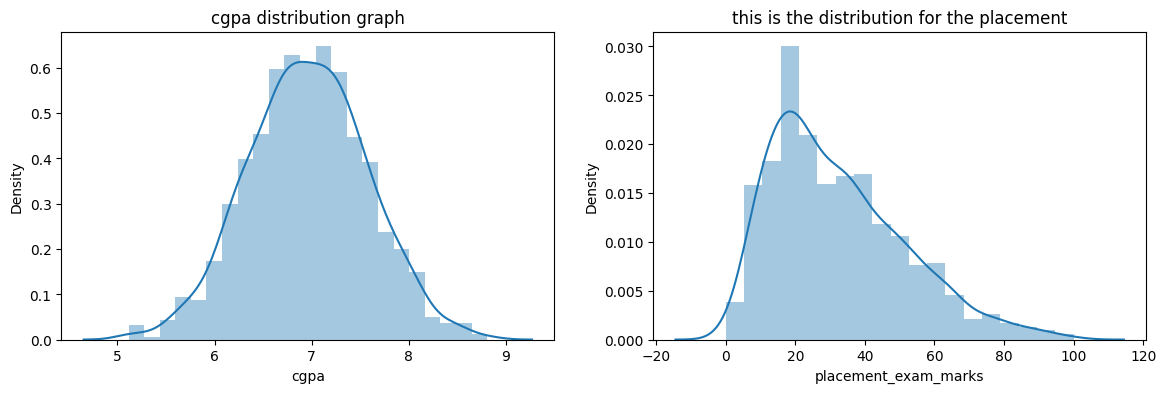

In [53]:
plt.figure(figsize = (14,4))
plt.subplot(1,2,1)
plt.title('cgpa distribution graph')
sns.distplot(df_new['cgpa'])

plt.subplot( 1,2,2)
sns.distplot(df_new['placement_exam_marks'])
plt.title("this is the distribution for the placement")

In [55]:
df_new.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961499,32.225000,0.489000
std,0.612688,19.130822,0.500129
min,5.113546,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,8.808934,100.000000,1.000000


<Axes: xlabel='placement_exam_marks'>

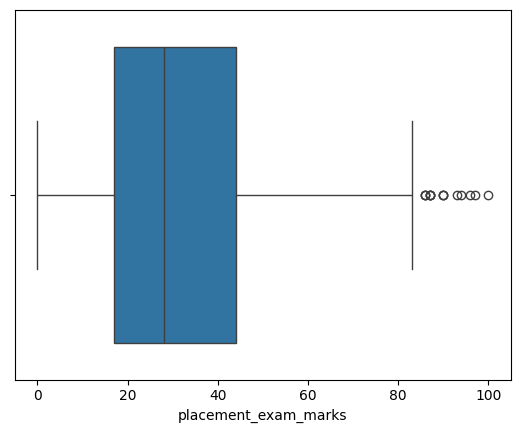

In [63]:
sns.boxplot(x =df_new['placement_exam_marks'])

In [64]:
percentile25 =df_new['placement_exam_marks'].quantile(0.25)
percentile75 = df_new['placement_exam_marks'].quantile(0.75)

In [65]:
percentile25

np.float64(17.0)

In [66]:
iqr = percentile75-percentile25

In [67]:
iqr

np.float64(27.0)

In [69]:
marks_upper_limit = percentile75+1.5*iqr
marks_lower_limit = percentile25-1.5*iqr

In [70]:
marks_lower_limit

np.float64(-23.5)

In [71]:
new_df_2 = df_new.copy()
new_df_2['placement_exam_marks']=np.where(
    new_df_2['placement_exam_marks']>marks_upper_limit,
    marks_upper_limit,
    np.where(
        new_df_2['placement_exam_marks']<marks_lower_limit,
        marks_lower_limit,
        new_df_2['placement_exam_marks']
    )
)

In [72]:
new_df_2

,cgpa,placement_exam_marks,placed
0,7.190000,26.0,1
1,7.460000,38.0,1
2,7.540000,40.0,1
3,6.420000,8.0,1
4,7.230000,17.0,0
...,...,...,...
995,8.808934,44.0,1
996,8.808934,65.0,1
997,5.113546,34.0,0
998,8.620000,46.0,1


/tmp/ipykernel_1527/3917680706.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_new['placement_exam_marks'])
/tmp/ipykernel_1527/3917680706.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df_2['placement_exam_marks'])


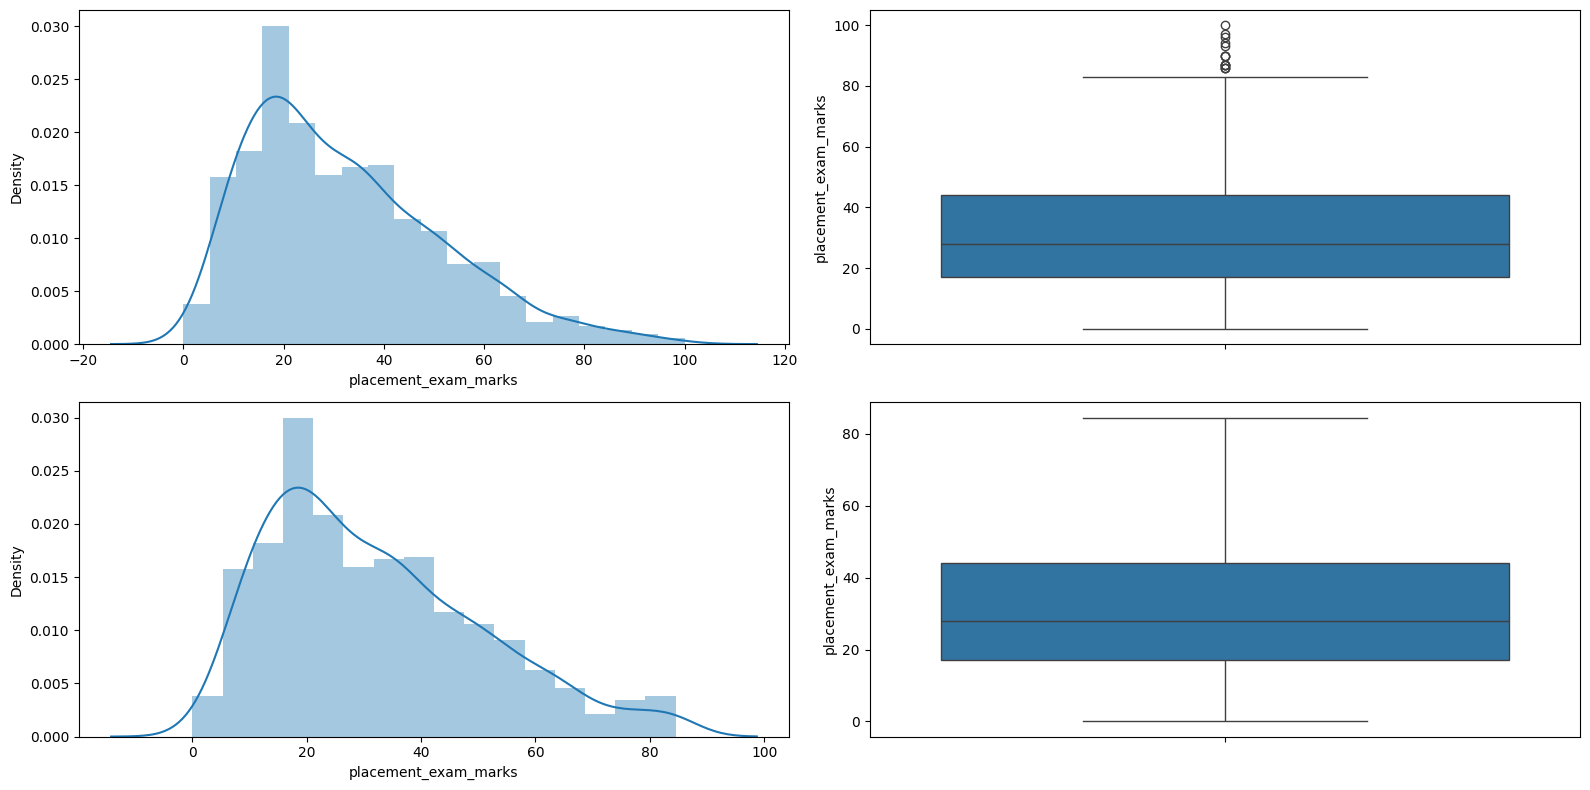

In [77]:
plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.distplot(df_new['placement_exam_marks'])

plt.subplot(2,2,2)
sns.boxplot(new_df['placement_exam_marks'])

plt.subplot(2,2,3)
sns.distplot(new_df_2['placement_exam_marks'])

plt.subplot(2,2,4)
sns.boxplot(new_df_2['placement_exam_marks'])
plt.tight_layout()
#

**outliers detection using percentile method**

In [78]:
df = pd.read_csv("/content/weight-height.csv")

In [79]:
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [81]:
df['Height'].describe()

,Height
count,10000.000000
mean,66.367560
std,3.847528
min,54.263133
25%,63.505620
50%,66.318070
75%,69.174262
max,78.998742


/tmp/ipykernel_1527/3557415962.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Height'],)


<Axes: xlabel='Height', ylabel='Density'>

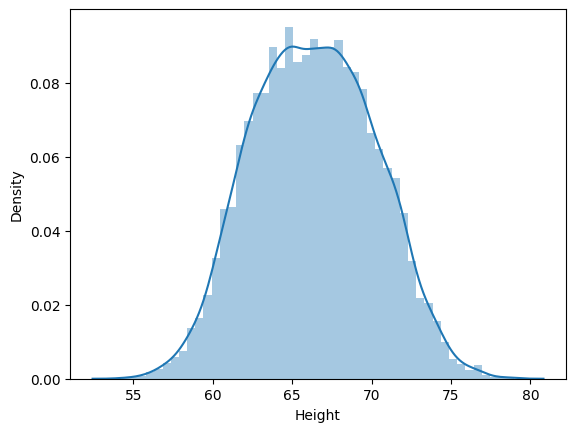

In [83]:
sns.distplot(df['Height'])

{'whiskers': [<matplotlib.lines.Line2D at 0x7d4a7b6760d0>,
 'caps': [<matplotlib.lines.Line2D at 0x7d4a7b676350>,
 'boxes': [<matplotlib.lines.Line2D at 0x7d4a7b675f90>],
 'medians': [<matplotlib.lines.Line2D at 0x7d4a7b6765d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7d4a7b676710>],
 'means': []}

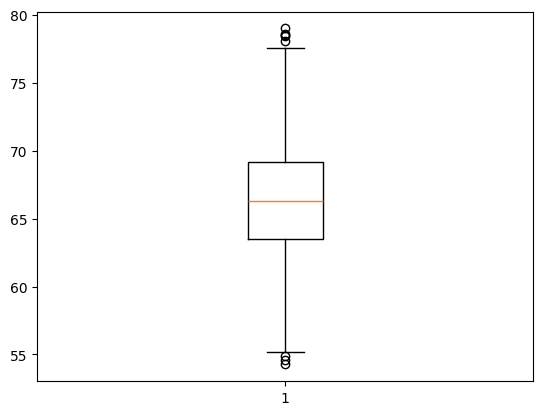

In [88]:
plt.boxplot(x=(df['Height']))

In [91]:
upper_limit = df['Height'].quantile(0.98)

In [92]:
upper_limit

np.float64(73.98591718768152)

In [93]:
lower_limit = df['Height'].quantile(0.02)

In [97]:
new_df= df[(df['Height']<=74.78) & (df['Height']>=58.13)]

In [98]:
new_df['Height'].describe()

,Height
count,9799.000000
mean,66.363507
std,3.644267
min,58.134496
25%,63.577147
50%,66.317899
75%,69.119859
max,74.767447


In [100]:
df['Height'].describe()

,Height
count,10000.000000
mean,66.367560
std,3.847528
min,54.263133
25%,63.505620
50%,66.318070
75%,69.174262
max,78.998742


<Axes: ylabel='Height'>

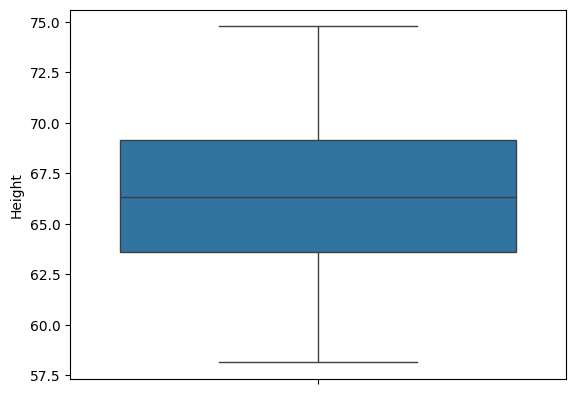

In [103]:
sns.boxplot(new_df['Height'])

/tmp/ipykernel_1527/1622920233.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df['Height'])


<Axes: xlabel='Height', ylabel='Density'>

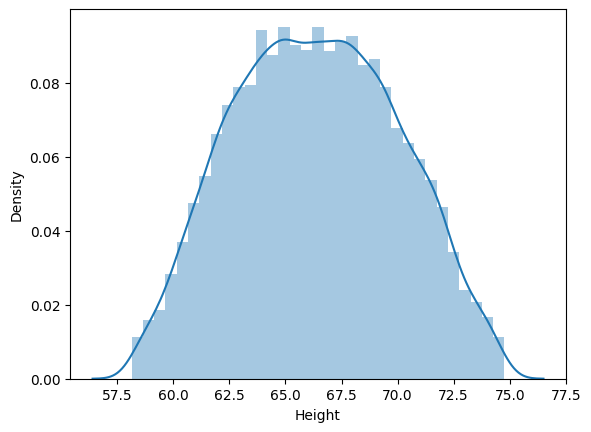

In [104]:
sns.distplot(new_df['Height'])

In [106]:

df['Height'] =np.where(df['Height']>=upper_limit,
         upper_limit,
         np.where(
             df['Height']<=lower_limit,
             lower_limit,
             df['Height']
         )
         )

/tmp/ipykernel_1527/3945773010.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Height'])


<Axes: xlabel='Height', ylabel='Density'>

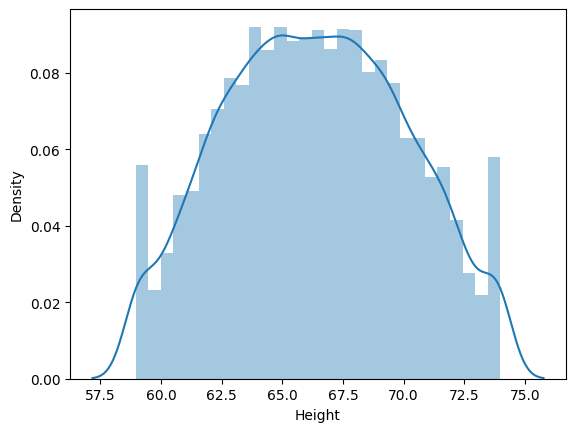

In [107]:
sns.distplot(df['Height'])